# PRCP-1009 – Cellphone Price Range Prediction
### Complete EDA, Data Preprocessing, Model Comparison, Feature Importance & Business Report

**Project objective:** Predict the price category of a mobile phone from its specifications. The target is a four-class label: `0 = Low`, `1 = Medium`, `2 = High`, and `3 = Very High`.

**Business context:** Bob wants to use historical mobile-phone specification and price-category data to position new products competitively. This notebook builds a classification model to support product planning. It does **not** predict an exact rupee price.

**Dataset:** `datasets_11167_15520_train.csv`

### Deliverables
1. Dataset inspection and exploratory data analysis (EDA).
2. Data quality assessment and preprocessing.
3. Comparison of multiple machine-learning classifiers.
4. Cross-validation, tuning, test-set evaluation, and error analysis.
5. Feature-importance interpretation.
6. Business recommendations, challenges, limitations, and production plan.

> Run all cells from top to bottom. The notebook includes saved outputs from the current dataset run. If you change the dataset or code, rerun all cells so the displayed results match your version.

## 1. Libraries and reproducibility

We use pandas and NumPy for data handling, Matplotlib and Seaborn for charts, and scikit-learn for machine learning. Fixed random seeds make the split and model comparisons reproducible.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

The CSV should be in the same folder as this notebook. In Google Colab, upload the file if it is not already available.

In [2]:
from pathlib import Path

DATA_FILE = Path("datasets_11167_15520_train.csv")

if not DATA_FILE.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("Please upload the cellphone training CSV.")
        DATA_FILE = Path(csv_names[0])
    except ImportError:
        raise FileNotFoundError(
            "Place datasets_11167_15520_train.csv beside this notebook and rerun."
        )

df = pd.read_csv(DATA_FILE)
print(f"Dataset loaded from: {DATA_FILE}")
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
display(df.head())

Dataset loaded from: datasets_11167_15520_train.csv
Rows: 2000 | Columns: 21


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0,1


## 3. Data understanding and quality assessment

The dataset contains mobile hardware and connectivity specifications. `price_range` is the target variable; all other columns are predictors.

### 3.1 Dataset structure and descriptive statistics

In [3]:
print("Dataset shape:", df.shape)
print("\nColumn data types and non-null counts:")
display(df.dtypes.rename("data_type").to_frame())
display(df.describe().T)

Dataset shape: (2000, 21)

Column data types and non-null counts:


,data_type
battery_power,int64
blue,int64
clock_speed,float64
dual_sim,int64
fc,int64
four_g,int64
int_memory,int64
m_dep,float64
mobile_wt,int64
n_cores,int64


,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.5185,439.4182,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.4950,0.5001,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.5223,0.8160,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.5095,0.5000,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.3095,4.3414,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.5215,0.4997,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.0465,18.1457,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.5018,0.2884,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.2490,35.3997,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.5205,2.2878,1.0,3.00,4.0,7.00,8.0


### 3.2 Missing values, duplicates, and target validation

Missing values and duplicated records are checked before analysis. Duplicate rows are not automatically removed without review because repeated feature combinations can be valid observations. The target must contain only the four expected classes.

In [4]:
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique()
})
display(quality)
duplicate_count = int(df.duplicated().sum())
print("Duplicate rows:", duplicate_count)
print("Target classes:", sorted(df["price_range"].dropna().unique().tolist()))
assert "price_range" in df.columns
assert set(df["price_range"].dropna().unique()).issubset({0, 1, 2, 3})

,missing_count,missing_percent,unique_values
battery_power,0,0.0,1094
blue,0,0.0,2
clock_speed,0,0.0,26
dual_sim,0,0.0,2
fc,0,0.0,20
four_g,0,0.0,2
int_memory,0,0.0,63
m_dep,0,0.0,10
mobile_wt,0,0.0,121
n_cores,0,0.0,8


Duplicate rows: 0
Target classes: [0, 1, 2, 3]


### 3.3 Target-class balance

The target distribution determines whether class imbalance needs special treatment. Stratification is used in splitting and cross-validation to preserve class proportions.

,count,percentage
price_range,,
0,500,25.0
1,500,25.0
2,500,25.0
3,500,25.0


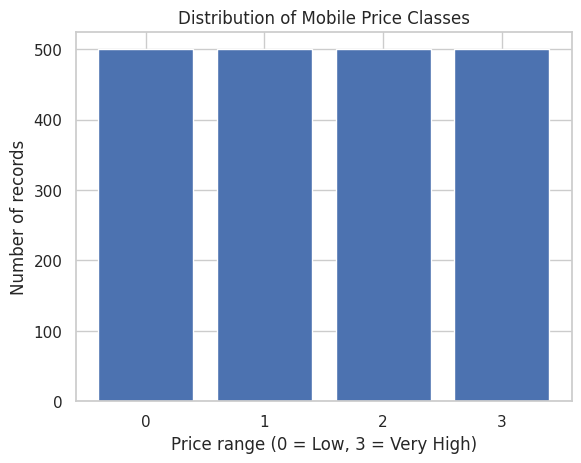

In [5]:
class_counts = df["price_range"].value_counts().sort_index()
class_percent = (class_counts / len(df) * 100).round(2)
target_summary = pd.DataFrame({"count": class_counts, "percentage": class_percent})
display(target_summary)

ax = plt.gca()
ax.bar(class_counts.index.astype(str), class_counts.values)
ax.set(title="Distribution of Mobile Price Classes",
       xlabel="Price range (0 = Low, 3 = Very High)", ylabel="Number of records")
plt.show()

**Observed data-quality findings for the supplied file:** the dataset has 2,000 rows and 21 columns (20 predictors and one target). There are no missing values and no duplicated rows. Each of the four price classes has 500 records (25%). Therefore, no imputation, duplicate deletion, oversampling, or undersampling is required for this file. A stratified split is still used to preserve this balanced distribution.

## 4. Exploratory Data Analysis

EDA is used to understand feature ranges, distributions, relationships, and differences between price classes. Charts are followed by interpretations to connect the observations to the modelling task.

### 4.1 Distributions of numerical features

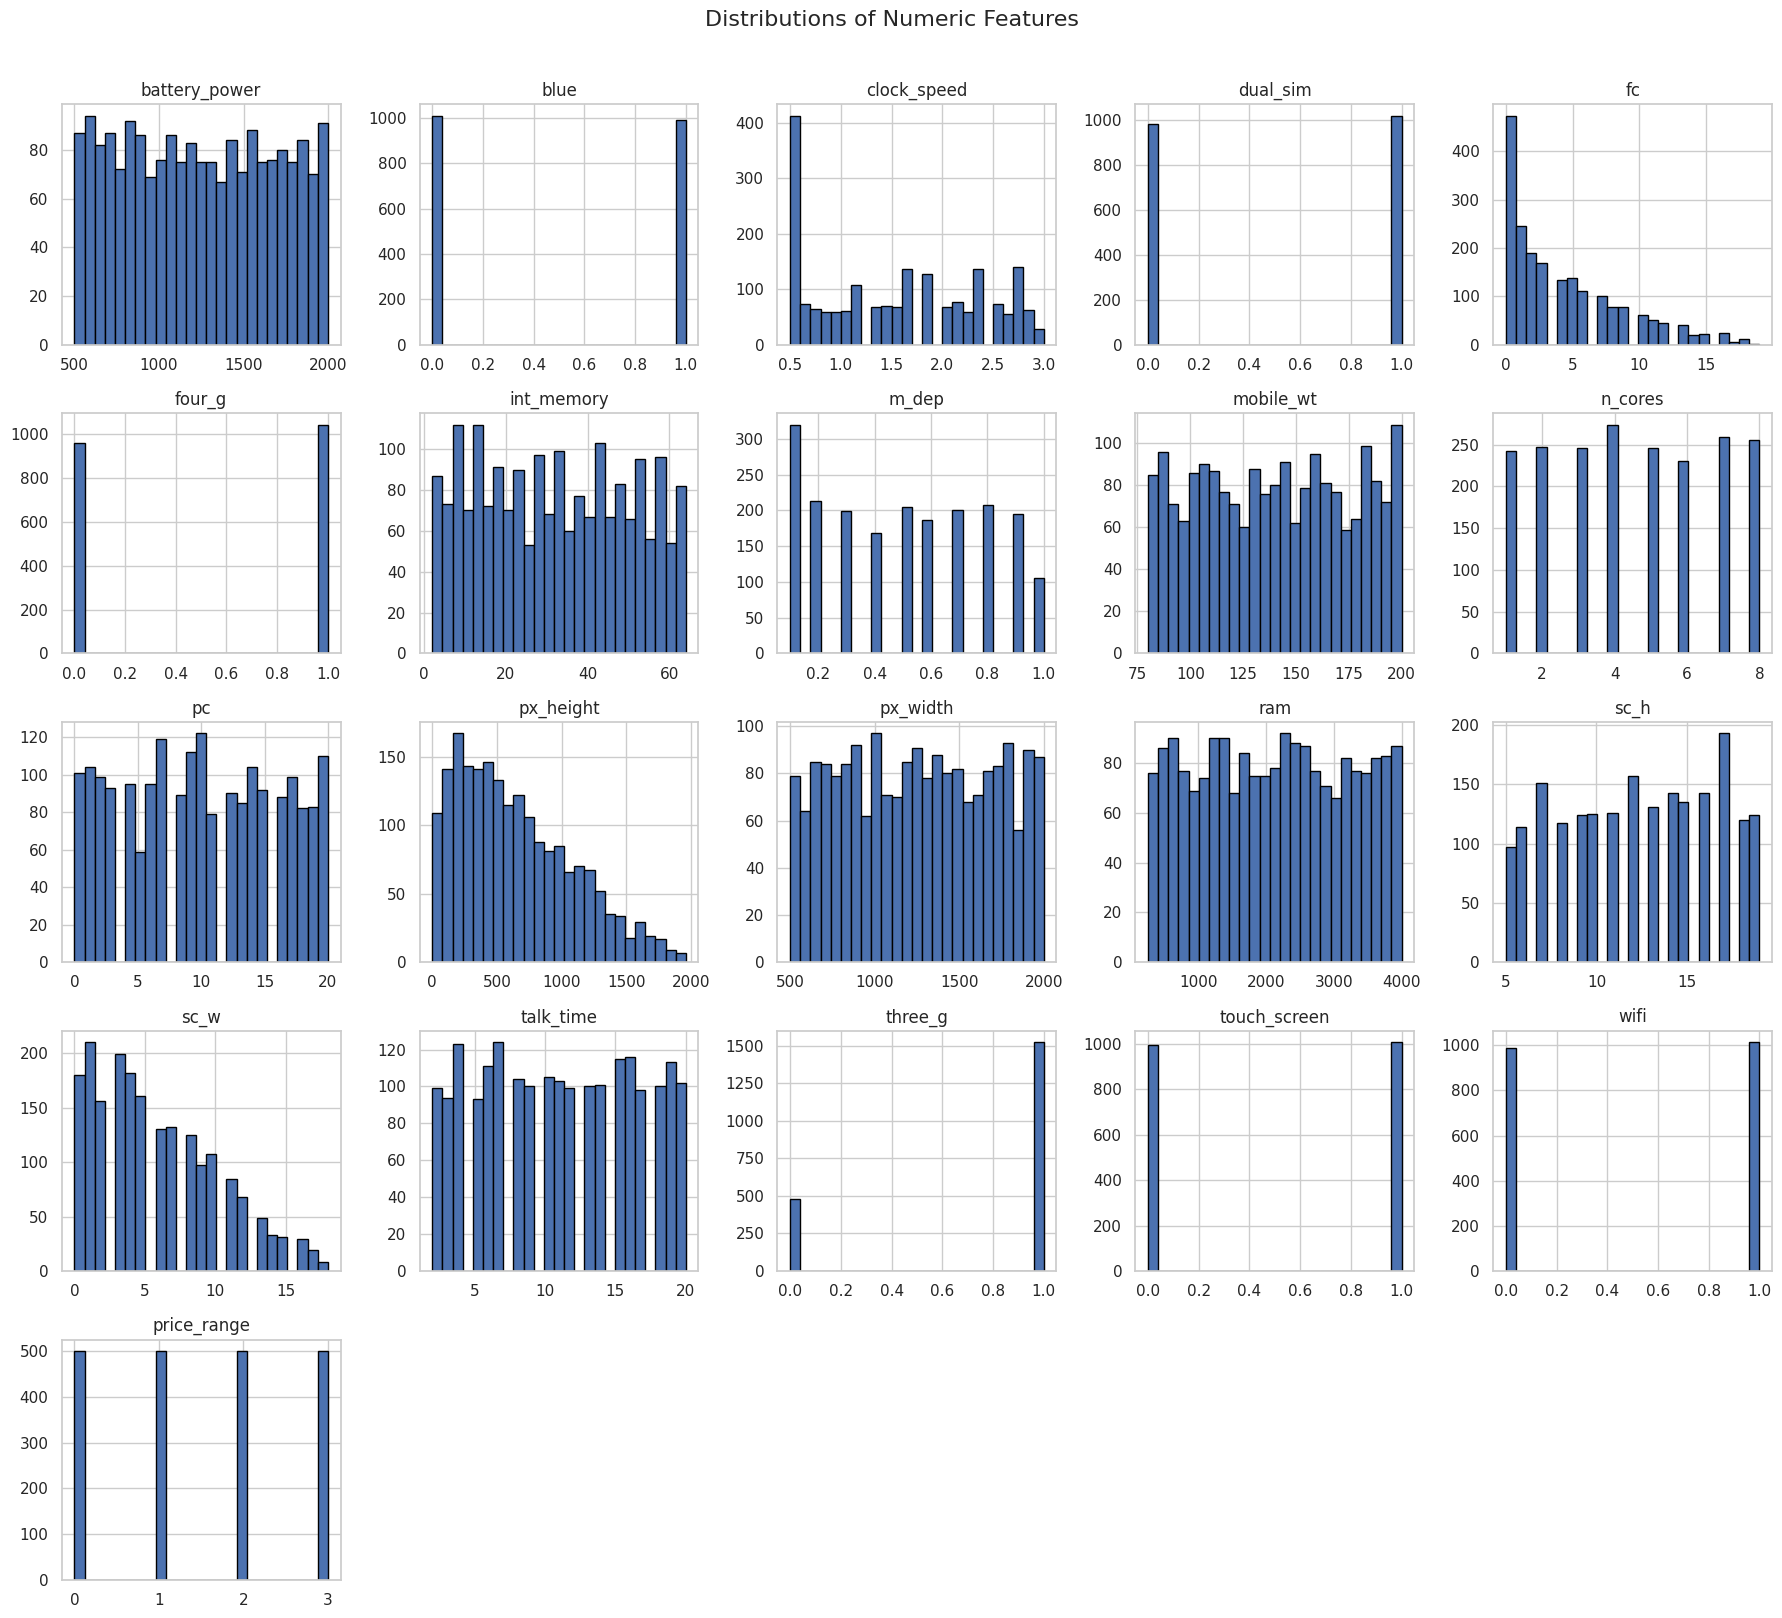

In [19]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols].hist(figsize=(18, 16), bins=25, edgecolor="black")
plt.suptitle("Distributions of Numeric Features", y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

**Interpretation:** The histograms show the spread and shape of each numeric feature. Binary variables take values 0 and 1, while hardware measurements such as RAM, battery power, dimensions, and pixel resolution vary over wider numeric ranges. The different scales matter for distance- and margin-based algorithms, so scaling is included in the Logistic Regression, KNN, and SVM pipelines.

### 4.2 Correlation with the target and between features

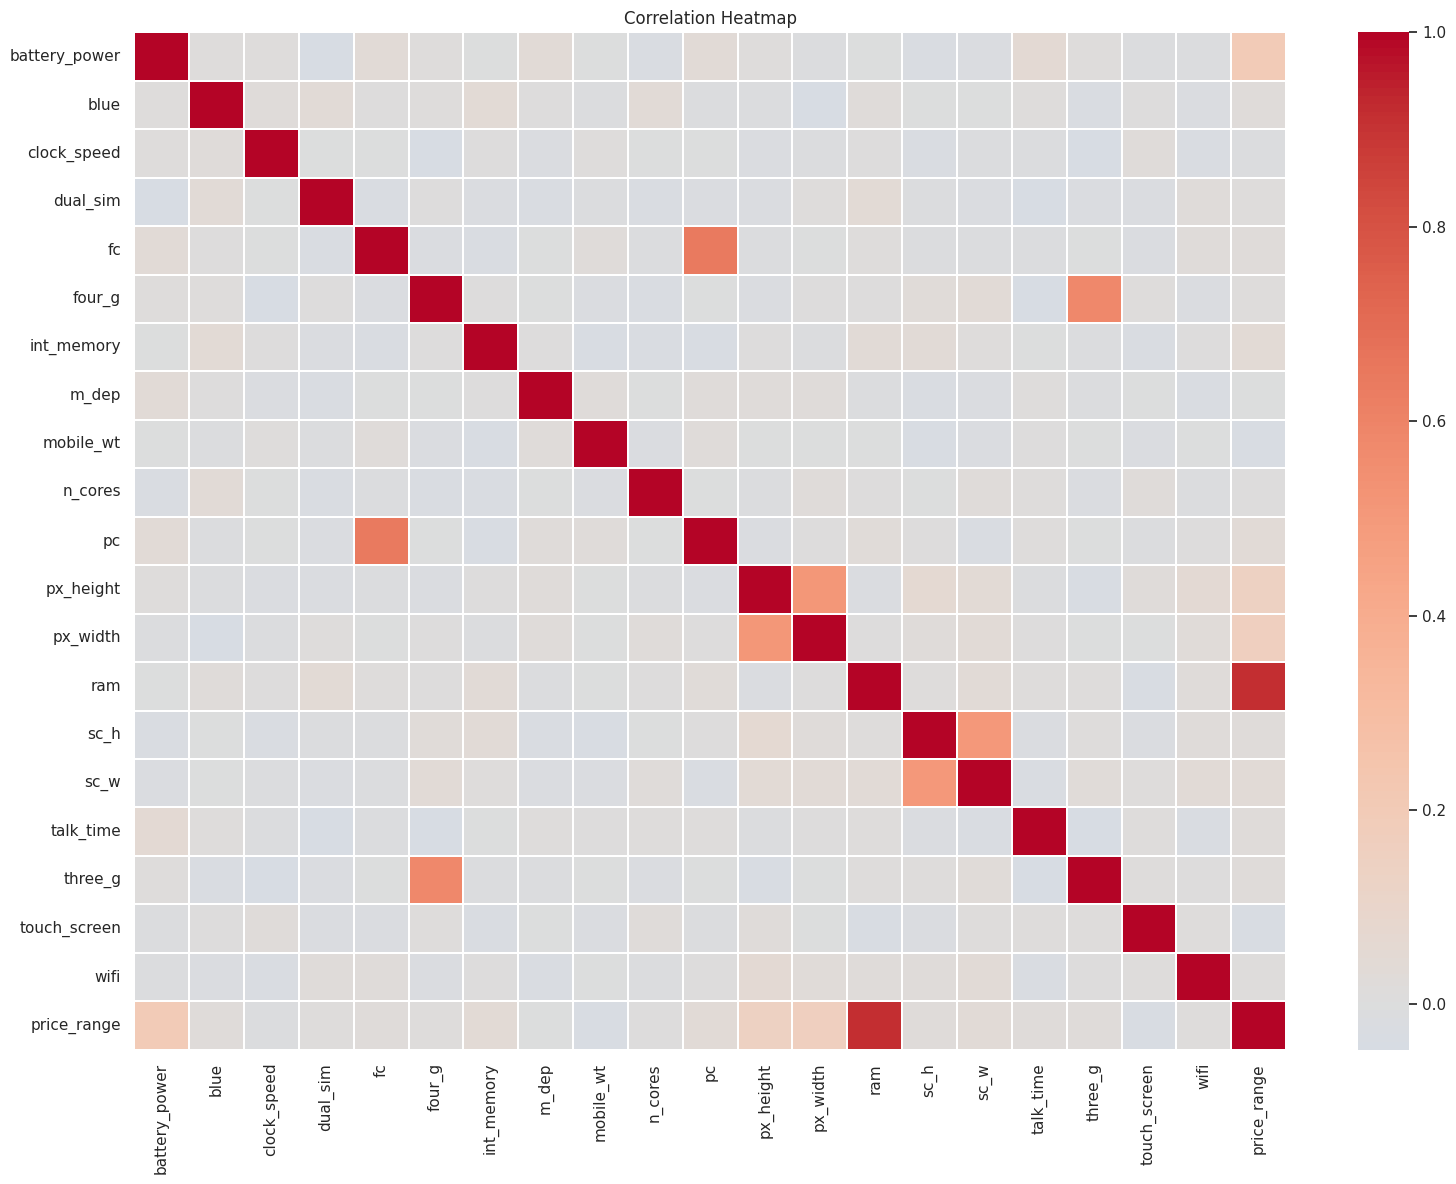

,correlation_with_price_range
ram,0.9170
battery_power,0.2007
px_width,0.1658
px_height,0.1489
int_memory,0.0444
sc_w,0.0387
pc,0.0336
touch_screen,-0.0304
mobile_wt,-0.0303
three_g,0.0236


Features with the largest absolute linear correlations:


,price_range
ram,0.9170
battery_power,0.2007
px_width,0.1658
px_height,0.1489
int_memory,0.0444
sc_w,0.0387
pc,0.0336
touch_screen,-0.0304


In [7]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.2)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

target_corr = corr["price_range"].drop("price_range").sort_values(
    key=lambda s: s.abs(), ascending=False
)
display(target_corr.rename("correlation_with_price_range").to_frame())
print("Features with the largest absolute linear correlations:")
display(target_corr.head(8).to_frame())

**Interpretation:** Correlation summarizes linear association and does not prove causation. Features with stronger positive or negative correlations are useful candidates for investigation, but a feature can still be predictive through a non-linear relationship even when its linear correlation is small. Correlation is therefore treated as an exploratory guide, not as the final feature-selection rule.

### 4.3 Numeric feature distributions by price class

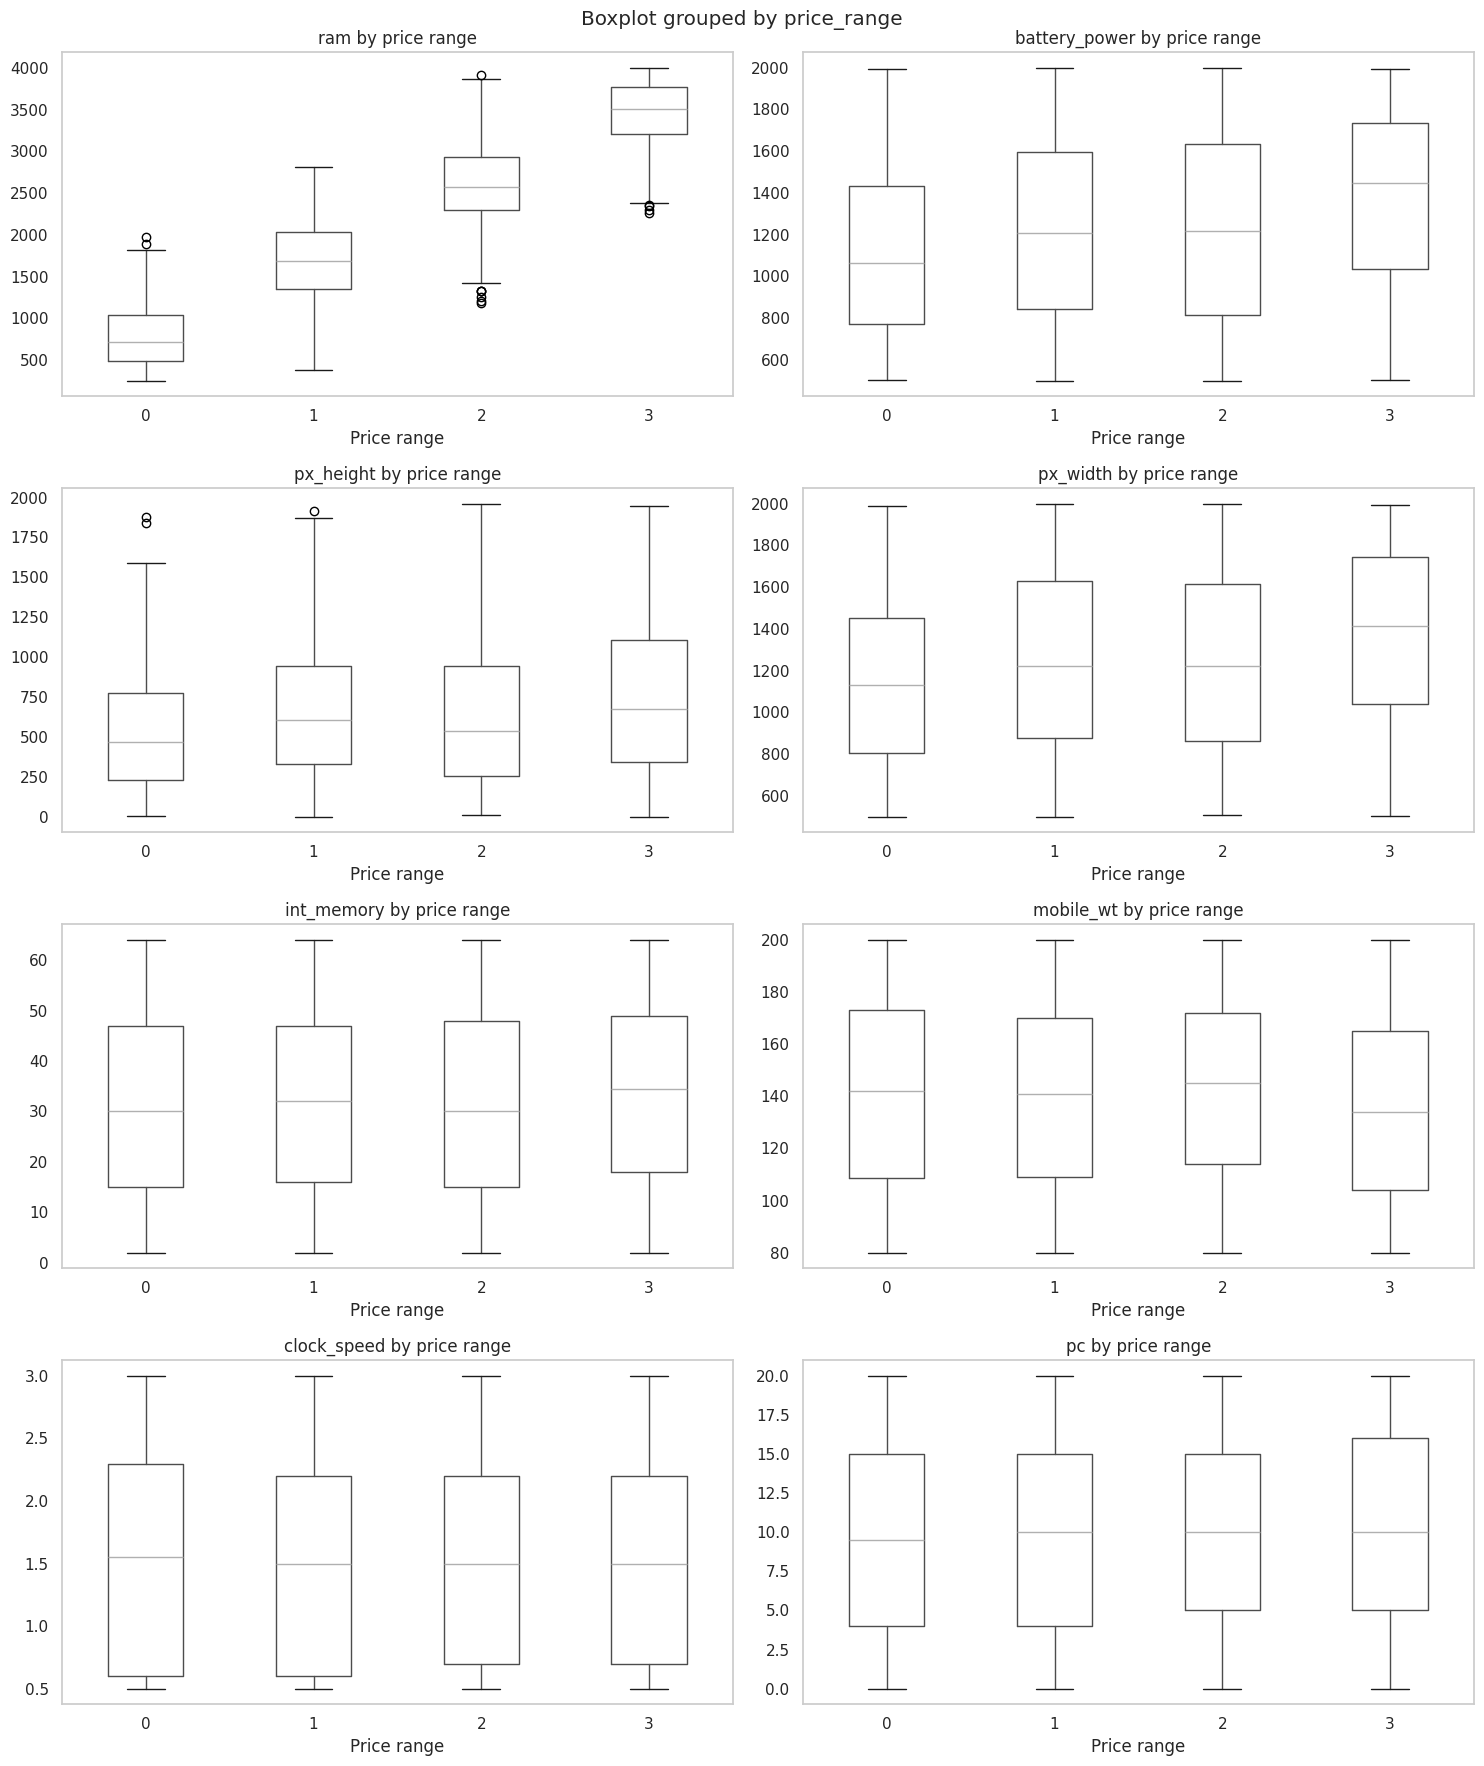

In [8]:
selected_features = [
    "ram", "battery_power", "px_height", "px_width",
    "int_memory", "mobile_wt", "clock_speed", "pc"
]
fig, axes = plt.subplots(4, 2, figsize=(15, 18))
for feature, ax in zip(selected_features, axes.flat):
    df.boxplot(column=feature, by="price_range", ax=ax, grid=False)
    ax.set_title(f"{feature} by price range")
    ax.set_xlabel("Price range")
plt.tight_layout()
plt.show()

**Interpretation:** Compare the medians, spread, and overlap between classes. Clear shifts between adjacent classes suggest that a feature may help distinguish price segments. Overlap indicates that no single feature is sufficient on its own and supports using a model that combines multiple specifications.

### 4.4 Connectivity and feature availability

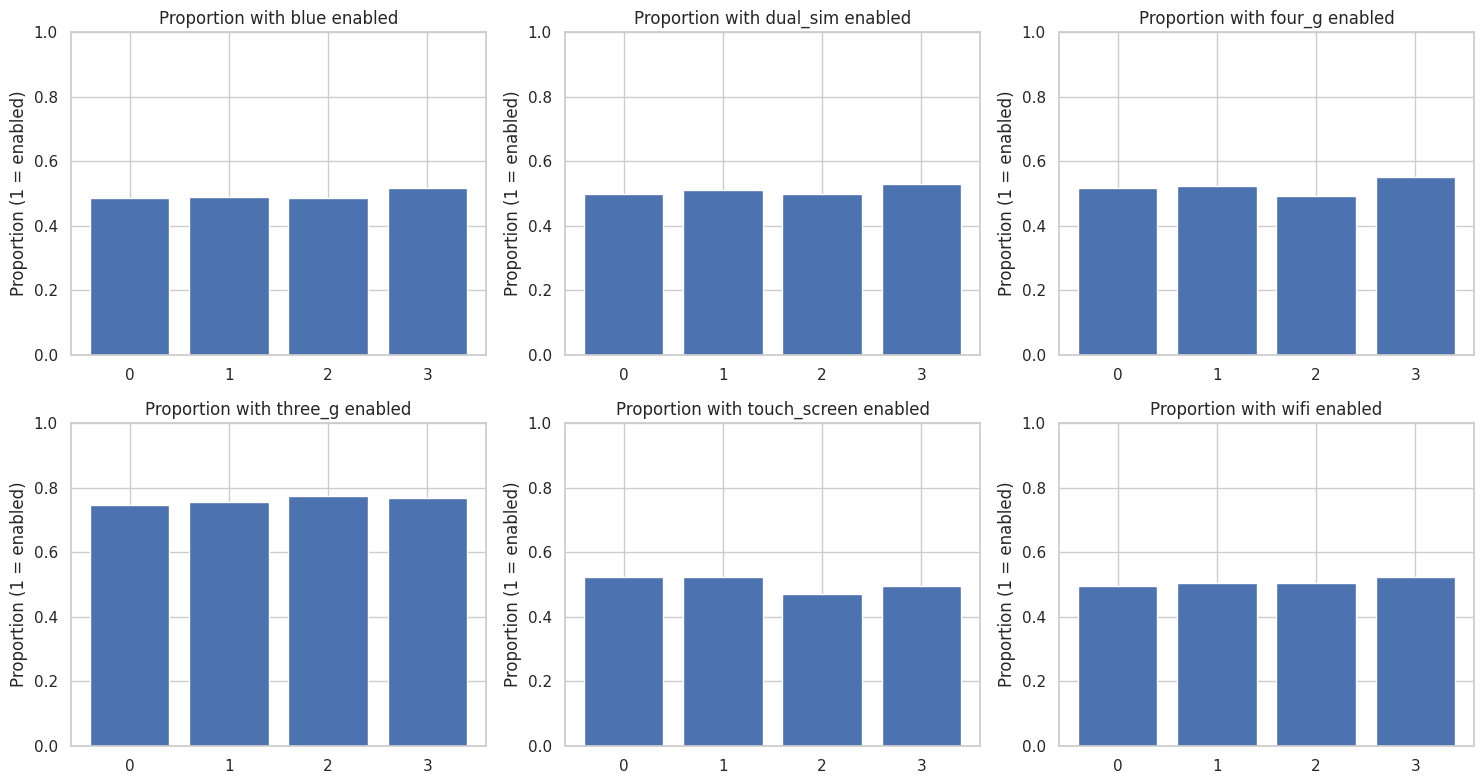

In [9]:
binary_features = ["blue", "dual_sim", "four_g", "three_g", "touch_screen", "wifi"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for feature, ax in zip(binary_features, axes.flat):
    means = df.groupby("price_range")[feature].mean().reindex([0, 1, 2, 3])
    ax.bar(means.index.astype(str), means.values)
    ax.set_title(f"Proportion with {feature} enabled")
    ax.set_ylabel("Proportion (1 = enabled)")
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

**Interpretation:** Since these variables are binary, the bar height represents the proportion of phones in each price class that have the feature enabled. A feature whose proportion changes substantially across price classes may contribute useful information, while a similar proportion across classes may have less discriminative value in this dataset.

## 5. Preprocessing and train-test split

This is a **supervised multi-class classification** task. We predict the categorical `price_range`, not a continuous selling price.

- `X` contains the 20 mobile specifications.
- `y` contains the four target labels.
- A stratified 80:20 split reserves a final test set.
- Imputation and scaling are placed inside pipelines so they are fitted only on training folds. No imputation is needed for the current complete dataset.
- Tree models do not need feature scaling; Logistic Regression, KNN, and SVM use StandardScaler.

In [10]:
X = df.drop(columns=["price_range"])
y = df["price_range"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Test class proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Training set: (1600, 20)
Test set: (400, 20)

Training class proportions:


,proportion
price_range,
0,0.25
1,0.25
2,0.25
3,0.25


Test class proportions:


,proportion
price_range,
0,0.25
1,0.25
2,0.25
3,0.25


## 6. Build and compare multiple classification models

The candidate models cover linear, tree-based, ensemble, distance-based, and kernel-based approaches. We use the same train/test split and report accuracy, macro precision, macro recall, macro F1, weighted F1, and fit/prediction time.

**Model-selection rule:** use mean 5-fold cross-validation macro F1 on the training set as the primary selection criterion. The test set is reserved for the final unbiased comparison and evaluation. Macro metrics give equal weight to each price class.

In [11]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", ExtraTreesClassifier(
            n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", GradientBoostingClassifier(random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=7))
    ]),
    "SVM (RBF)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf"))
    ])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted"
}

results = []
fitted_models = {}
cv_records = []

for model_name, estimator in models.items():
    start = time.perf_counter()
    cv_result = cross_validate(
        estimator, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=-1, return_train_score=False
    )
    cv_seconds = time.perf_counter() - start

    estimator.fit(X_train, y_train)
    fitted_models[model_name] = estimator

    pred_start = time.perf_counter()
    y_pred = estimator.predict(X_test)
    prediction_seconds = time.perf_counter() - pred_start

    results.append({
        "Model": model_name,
        "CV macro F1 mean": cv_result["test_f1_macro"].mean(),
        "CV macro F1 std": cv_result["test_f1_macro"].std(),
        "Test accuracy": accuracy_score(y_test, y_pred),
        "Test precision macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Test recall macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "Test F1 macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Test F1 weighted": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "CV time (sec)": cv_seconds,
        "Prediction time (sec)": prediction_seconds
    })

comparison = pd.DataFrame(results).sort_values(
    ["CV macro F1 mean", "Test F1 macro"], ascending=False
).reset_index(drop=True)

display(comparison.style.format({
    col: "{:.4f}" for col in comparison.columns if col != "Model"
}))

,Model,CV macro F1 mean,CV macro F1 std,Test accuracy,Test precision macro,Test recall macro,Test F1 macro,Test F1 weighted,CV time (sec),Prediction time (sec)
0,Logistic Regression,0.9480,0.0098,0.9650,0.9650,0.9650,0.9650,0.9650,3.1993,0.0035
1,Gradient Boosting,0.8884,0.0188,0.9125,0.9124,0.9125,0.9123,0.9123,11.8859,0.0120
2,Random Forest,0.8706,0.0317,0.8800,0.8805,0.8800,0.8802,0.8802,10.2876,0.0893
3,Extra Trees,0.8627,0.0270,0.8825,0.8821,0.8825,0.8822,0.8822,4.6296,0.0918
4,SVM (RBF),0.8585,0.0096,0.8950,0.8969,0.8950,0.8956,0.8956,1.0056,0.0446
5,Decision Tree,0.8158,0.0116,0.8300,0.8319,0.8300,0.8302,0.8302,0.3830,0.0042
6,KNN,0.5241,0.0127,0.5175,0.5267,0.5175,0.5199,0.5199,0.3065,0.0557


### 6.1 Visual model comparison

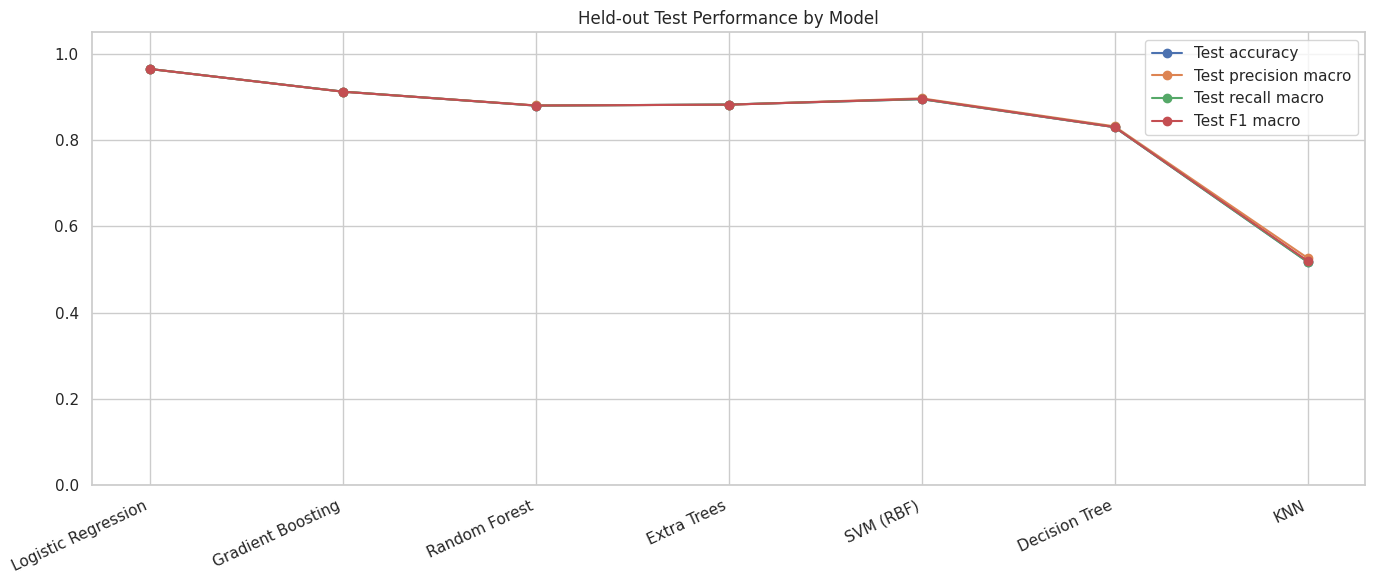

Selected model using training CV macro F1: Logistic Regression


In [12]:
metrics_to_plot = [
    "Test accuracy", "Test precision macro",
    "Test recall macro", "Test F1 macro"
]
plot_df = comparison.melt(
    id_vars="Model", value_vars=metrics_to_plot,
    var_name="Metric", value_name="Score"
)
plt.figure(figsize=(14, 6))
for metric in metrics_to_plot:
    subset = comparison.set_index("Model")[metric]
    plt.plot(subset.index, subset.values, marker="o", label=metric)
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend()
plt.title("Held-out Test Performance by Model")
plt.tight_layout()
plt.show()

best_model_name = comparison.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
print("Selected model using training CV macro F1:", best_model_name)

**Interpretation:** Compare macro F1 and per-class metrics rather than relying only on accuracy. Training time and prediction time are included as practical deployment considerations. The model selected in this notebook is the model with the highest mean cross-validation macro F1 on the training partition; the held-out test scores provide its final evaluation.

## 7. Hyperparameter tuning of the leading model

We tune the selected model using GridSearchCV on the training data only. The parameter grid is selected according to the estimator type. All preprocessing remains inside the pipeline, so transformations are refitted independently within each cross-validation fold.

In [13]:
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.1, 1.0, 5.0]
    },
    "Decision Tree": {
        "classifier__max_depth": [None, 8, 15],
        "classifier__min_samples_leaf": [1, 3, 5]
    },
    "Random Forest": {
        "classifier__n_estimators": [200, 400],
        "classifier__max_depth": [None, 15],
        "classifier__min_samples_leaf": [1, 2]
    },
    "Extra Trees": {
        "classifier__n_estimators": [200, 400],
        "classifier__max_depth": [None, 15],
        "classifier__min_samples_leaf": [1, 2]
    },
    "Gradient Boosting": {
        "classifier__n_estimators": [100, 150],
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__max_depth": [2, 3]
    },
    "KNN": {
        "classifier__n_neighbors": [5, 7, 9, 11],
        "classifier__weights": ["uniform", "distance"]
    },
    "SVM (RBF)": {
        "classifier__C": [1, 5, 10],
        "classifier__gamma": ["scale", 0.01, 0.1]
    }
}

grid = GridSearchCV(
    estimator=models[best_model_name],
    param_grid=param_grids[best_model_name],
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)
grid.fit(X_train, y_train)

tuned_model = grid.best_estimator_
print("Selected model:", best_model_name)
print("Best parameters:", grid.best_params_)
print("Best cross-validation macro F1:", round(grid.best_score_, 4))

Selected model: Logistic Regression
Best parameters: {'classifier__C': 5.0}
Best cross-validation macro F1: 0.9599


## 8. Final test-set evaluation

The test set has not been used to fit preprocessing, select hyperparameters, or train the model. It is now used for the final evaluation of the tuned model.

In [14]:
final_predictions = tuned_model.predict(X_test)

final_metrics = pd.DataFrame([{
    "Model": best_model_name + " (tuned)",
    "Accuracy": accuracy_score(y_test, final_predictions),
    "Precision (macro)": precision_score(y_test, final_predictions, average="macro", zero_division=0),
    "Recall (macro)": recall_score(y_test, final_predictions, average="macro", zero_division=0),
    "F1-score (macro)": f1_score(y_test, final_predictions, average="macro", zero_division=0),
    "F1-score (weighted)": f1_score(y_test, final_predictions, average="weighted", zero_division=0)
}])
display(final_metrics.style.format({
    col: "{:.4f}" for col in final_metrics.columns if col != "Model"
}))

print(classification_report(
    y_test, final_predictions,
    labels=[0, 1, 2, 3],
    target_names=["Low", "Medium", "High", "Very High"],
    zero_division=0
))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),F1-score (weighted)
0,Logistic Regression (tuned),0.9675,0.9677,0.9675,0.9675,0.9675


              precision    recall  f1-score   support

         Low       0.99      0.97      0.98       100
      Medium       0.97      0.96      0.96       100
        High       0.95      0.96      0.96       100
   Very High       0.96      0.98      0.97       100

    accuracy                           0.97       400
   macro avg       0.97      0.97      0.97       400
weighted avg       0.97      0.97      0.97       400



### 8.1 Confusion matrix and error analysis

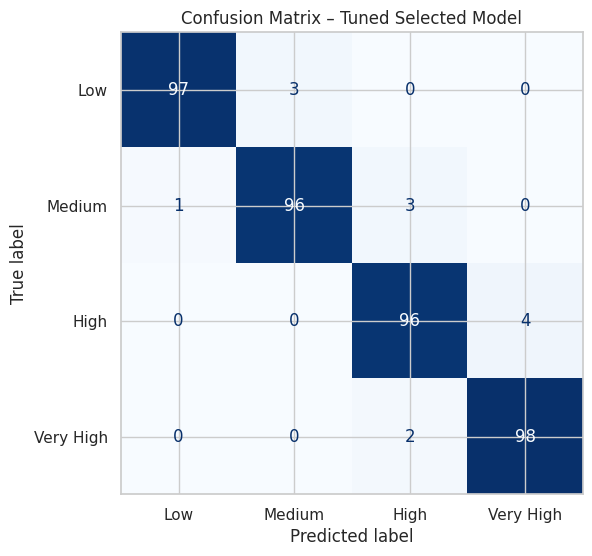

Misclassified test records: 13 out of 400


,Actual,Predicted,count
3,2,3,4
0,0,1,3
2,1,2,3
4,3,2,2
1,1,0,1


In [15]:
cm = confusion_matrix(y_test, final_predictions, labels=[0, 1, 2, 3])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High", "Very High"]
)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
plt.title("Confusion Matrix – Tuned Selected Model")
plt.show()

errors = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": final_predictions
})
errors = errors[errors["Actual"] != errors["Predicted"]]
print("Misclassified test records:", len(errors), "out of", len(y_test))
if len(errors):
    display(errors.groupby(["Actual", "Predicted"]).size()
            .rename("count").reset_index()
            .sort_values("count", ascending=False).head(10))

**Interpretation:** Diagonal cells are correct predictions; off-diagonal cells are errors. Review whether errors tend to occur between adjacent price classes or between distant classes. Misclassifying a high-cost phone as very high-cost may have a different business consequence from classifying a low-cost phone as very high-cost. The business should define the cost of each error before deployment.

## 9. Feature importance

Permutation importance is calculated on the held-out test set. It measures how much the selected model's macro F1 changes when one feature is randomly shuffled. A larger positive decrease indicates that the model relies more on that feature for predictive performance.

This method works with the full pipeline and provides a consistent importance approach even when the selected model is not tree-based. Importance indicates predictive contribution, not causation or a rupee-value effect.

,Feature,Importance mean,Importance std
0,ram,0.6879,0.0223
1,battery_power,0.2217,0.0144
2,px_width,0.1113,0.0126
3,px_height,0.1004,0.0108
4,mobile_wt,0.0105,0.0072
5,n_cores,0.0054,0.0027
6,m_dep,0.0017,0.0040
7,touch_screen,0.0015,0.0018
8,sc_w,0.0011,0.0024
9,int_memory,-0.0005,0.0044


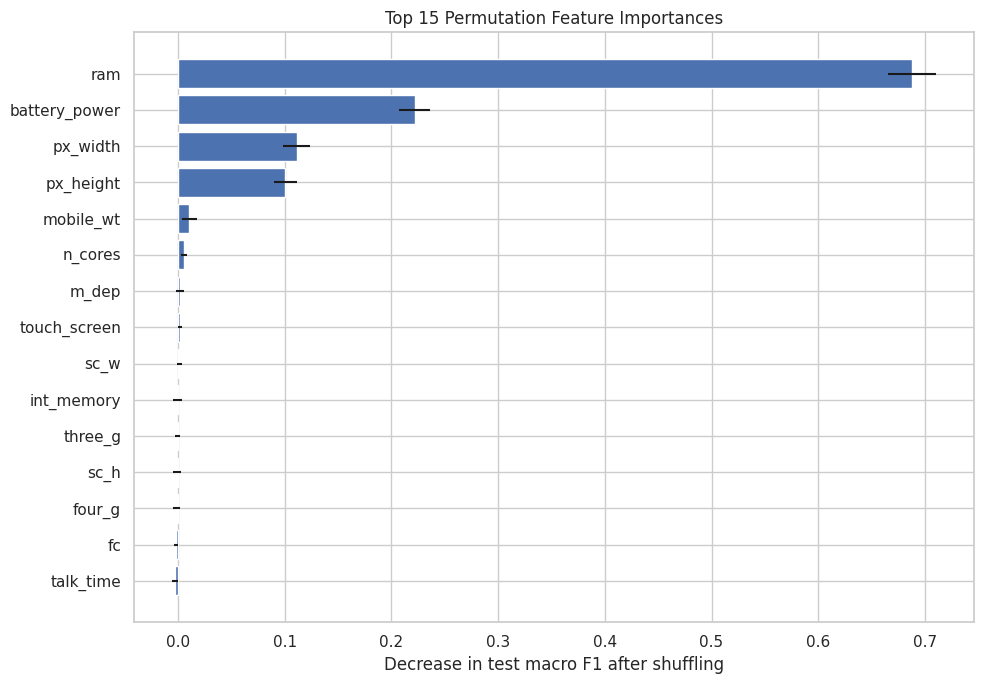

Top five features according to permutation importance:


,Feature,Importance mean,Importance std
0,ram,0.6879,0.0223
1,battery_power,0.2217,0.0144
2,px_width,0.1113,0.0126
3,px_height,0.1004,0.0108
4,mobile_wt,0.0105,0.0072


In [16]:
perm = permutation_importance(
    tuned_model, X_test, y_test,
    n_repeats=20, random_state=RANDOM_STATE,
    scoring="f1_macro", n_jobs=-1
)
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance mean": perm.importances_mean,
    "Importance std": perm.importances_std
}).sort_values("Importance mean", ascending=False).reset_index(drop=True)

display(importance.head(20))
top15 = importance.head(15).sort_values("Importance mean")
plt.figure(figsize=(10, 7))
plt.barh(top15["Feature"], top15["Importance mean"],
         xerr=top15["Importance std"])
plt.xlabel("Decrease in test macro F1 after shuffling")
plt.title("Top 15 Permutation Feature Importances")
plt.tight_layout()
plt.show()

print("Top five features according to permutation importance:")
display(importance.head(5))

### 9.1 Business interpretation of feature importance

Use the ranked feature table generated above to identify which specifications are most informative for the model. If RAM, battery power, or pixel resolution ranks highly, Bob can investigate those specifications when designing product tiers. Lower-ranked features may still matter for customer expectations, regulations, or competitive positioning even if they add less predictive information in this dataset.

Do not interpret importance as proof that changing a feature will cause a specific price increase. Validate product decisions with component costs, customer research, competitor pricing, and controlled market tests.

## 10. Business recommendations: how the model can help Bob

### 10.1 Product segmentation
The classifier can assign a proposed phone configuration to a low, medium, high, or very-high price segment. This gives the product team a consistent first estimate of market positioning based on historical examples.

### 10.2 Specification planning
Feature-importance results can guide further investigation into specifications that distinguish price classes. Bob can compare alternative combinations of RAM, battery capacity, internal storage, camera resolution, processor cores, and connectivity before finalizing a product.

### 10.3 Portfolio strategy
- **Low-cost range:** prioritize essential functions, affordability, and component efficiency.
- **Medium-cost range:** balance RAM, battery, storage, display, and camera capabilities.
- **High-cost range:** provide stronger performance and an improved overall user experience.
- **Very-high-cost range:** develop premium configurations supported by customer research and competitor analysis.

### 10.4 Inventory and procurement
When combined with sales forecasts and supplier information, segment predictions can support component planning and inventory decisions. The classifier alone does not forecast demand or component requirements.

### 10.5 Marketing and sales
Predicted segments can help organize product catalogs, campaign positioning, and customer recommendations. Actual customer targeting requires customer and sales information in addition to device specifications.

### 10.6 Financial decision support
The model predicts historical price categories, not exact selling prices or profitability. To calculate a profitable selling price, Bob must also consider bill of materials, labour, logistics, taxes, warranty, channel margins, competitor prices, and customer willingness to pay.

## 11. Example prediction for a proposed phone

The example specifications below are illustrative. Replace them with a real proposed phone's values. The feature names and order are taken directly from the training data to prevent input mismatch.

In [17]:
example_phone = pd.DataFrame([{
    "battery_power": 1800,
    "blue": 1,
    "clock_speed": 2.0,
    "dual_sim": 1,
    "fc": 8,
    "four_g": 1,
    "int_memory": 64,
    "m_dep": 0.7,
    "mobile_wt": 180,
    "n_cores": 8,
    "pc": 16,
    "px_height": 1920,
    "px_width": 1080,
    "ram": 4000,
    "sc_h": 15,
    "sc_w": 7,
    "talk_time": 18,
    "three_g": 1,
    "touch_screen": 1,
    "wifi": 1
}])[X.columns]

predicted_class = int(tuned_model.predict(example_phone)[0])
class_names = {0: "Low Cost", 1: "Medium Cost", 2: "High Cost", 3: "Very High Cost"}
print("Predicted price class:", predicted_class)
print("Predicted price segment:", class_names[predicted_class])

if hasattr(tuned_model, "predict_proba"):
    probs = tuned_model.predict_proba(example_phone)[0]
    display(pd.DataFrame({
        "Price segment": [class_names[int(c)] for c in tuned_model.classes_],
        "Probability": probs
    }).sort_values("Probability", ascending=False))

Predicted price class: 3
Predicted price segment: Very High Cost


,Price segment,Probability
3,Very High Cost,1.0000e+00
2,High Cost,5.6608e-10
1,Medium Cost,3.1580e-22
0,Low Cost,3.4851e-40


## 12. Challenges faced and techniques used

| Challenge | Technique / decision | Reason |
|---|---|---|
| Understanding the specification fields | Reviewed the data dictionary, column types, and descriptive statistics | Ensures features are interpreted correctly. |
| Missing data | Checked every column; no imputation required for this file | The supplied dataset has zero missing values. |
| Duplicate records | Checked exact duplicate rows; no rows removed | There are no exact duplicate rows in this file. |
| Class imbalance | Inspected target counts and used stratified splitting | All four classes have 500 examples each, so resampling is not necessary. |
| Different feature scales | StandardScaler inside Logistic Regression, KNN, and SVM pipelines | Distance- and margin-based algorithms are scale-sensitive. |
| Multi-class target | Used multi-class classifiers and macro metrics | The output is one of four categories, not a continuous value. |
| Model selection uncertainty | Compared seven algorithms using stratified cross-validation | Reduces dependence on one train/test split. |
| Hyperparameter selection | GridSearchCV applied only to training data | Keeps the test set independent from tuning. |
| Data leakage risk | Preprocessing steps included inside pipelines | Each CV fold learns transformations from its own training fold. |
| Model explainability | Used test-set permutation importance | Shows which features most affect predictive performance. |
| Market changes | Recommended periodic monitoring and retraining | Historical price classes may not represent current market conditions. |

### Additional limitations
1. The dataset has 2,000 records; it may not represent every brand, country, customer group, or current phone generation.
2. `price_range` is a class label, not an exact price in rupees.
3. The data description does not provide a confirmed collection date, market region, or sampling methodology.
4. Correlated features can share or obscure importance.
5. A strong random-split test result does not guarantee performance on future market data.
6. Business profitability cannot be inferred without cost, margin, competitor, and demand data.

## 13. Production recommendation

The selected model is determined from the training-set cross-validation macro F1 score and tuned using GridSearchCV. The final test metrics and confusion matrix should be reviewed before deployment.

### Production checklist
1. Validate the dataset's market region, collection period, and representativeness.
2. Collect current product specifications and actual selling-price categories.
3. Tune and compare models using stratified cross-validation.
4. Keep a separate recent holdout dataset for final evaluation.
5. Save the complete fitted pipeline, including preprocessing.
6. Validate incoming feature names, data types, ranges, and missing values.
7. Monitor class-wise precision/recall, prediction distribution, and drift.
8. Retrain when new verified product and price data becomes available.

**Recommendation:** Deploy the selected model only after the business confirms that its test performance and error costs are acceptable. A simple, stable model may be preferable to a slightly more accurate but slower or harder-to-maintain model.

In [18]:
# Save the tuned, complete pipeline and supporting metadata.
MODEL_PATH = "PRCP_1009_cellphone_price_model.joblib"
model_bundle = {
    "model": tuned_model,
    "feature_columns": X.columns.tolist(),
    "class_names": class_names,
    "selected_model": best_model_name,
    "best_parameters": grid.best_params_,
    "test_metrics": final_metrics.to_dict(orient="records")[0]
}
joblib.dump(model_bundle, MODEL_PATH)
print("Saved model bundle:", MODEL_PATH)

Saved model bundle: PRCP_1009_cellphone_price_model.joblib


## 14. Final conclusion

This project developed a supervised multi-class classification workflow to predict mobile-phone price categories from 20 product specifications. The dataset was inspected for missing values, duplicates, class balance, feature distributions, and correlations. The supplied data contains 2,000 rows, no missing values, no exact duplicate rows, and 500 examples in each of the four target classes.

Seven classification approaches were compared using stratified cross-validation and held-out test metrics. The leading candidate was tuned using GridSearchCV on the training partition, then evaluated on the untouched test partition using accuracy, macro precision, macro recall, macro F1, a classification report, and a confusion matrix. Permutation importance was used to rank the specifications that contribute most to the selected model's predictions.

The resulting model can support Bob's product planning by suggesting a likely price segment for a proposed specification combination. It can also help the company investigate which features distinguish historical price categories. However, the output is a price range, not an exact selling price. Before commercial use, the company should validate the model with current market data and combine it with component costs, competitor prices, customer demand, taxes, and distribution margins.

**Final model, tuned parameters, test metrics, and feature-importance rankings are reported in the executed output cells above.**

---
### Submission checklist
- [ ] Run all cells from top to bottom.
- [ ] Confirm the CSV path and dataset shape.
- [ ] Check that the model comparison table and final metrics display correctly.
- [ ] Review the actual top features and model-selection result.
- [ ] Confirm that `PRCP_1009_cellphone_price_model.joblib` is generated.
- [ ] Submit this `.ipynb` notebook as the single project notebook deliverable.